# Setup

In [5]:
# from google.colab import files
# files.upload()

!pip install kagglehub


In [6]:
import kagglehub
from google.colab import userdata
import os
os.environ["KAGGLE_USERNAME"] = userdata.get('KAGGLE_USERNAME')
os.environ["KAGGLE_KEY"] = userdata.get('KAGGLE_KEY')

path = kagglehub.dataset_download("yash92328/ai4mars-terrainaware-autonomous-driving-on-mars")
print(path)

100%|██████████| 5.72G/5.72G [04:57<00:00, 20.6MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/yash92328/ai4mars-terrainaware-autonomous-driving-on-mars/versions/1


In [7]:
import glob

MSL = glob.glob(os.path.join(path, "**", "msl"), recursive=True)[0]
print("msl folder:", MSL)

EDR_DIR = os.path.join(MSL, "images", "edr")
MXY_DIR = os.path.join(MSL, "images", "mxy")
RNG_DIR = os.path.join(MSL, "images", "rng-30m")
TRAIN_LABEL_DIR = os.path.join(MSL, "labels", "train")
print(os.listdir(os.path.join(MSL, "labels", "test")))

msl folder: /root/.cache/kagglehub/datasets/yash92328/ai4mars-terrainaware-autonomous-driving-on-mars/versions/1/ai4mars-dataset-merged-0.1/msl
['masked-gold-min3-100agree', 'masked-gold-min2-100agree', 'masked-gold-min1-100agree']


In [8]:
TEST_LABEL_DIR = os.path.join(MSL, "labels", "test", "masked-gold-min3-100agree")

for name, d in [("edr", EDR_DIR), ("mxy", MXY_DIR), ("rng", RNG_DIR),
                ("train labels", TRAIN_LABEL_DIR), ("test labels", TEST_LABEL_DIR)]:
    files = sorted(os.listdir(d))
    print(f"{name}: {len(files)} files, e.g. {files[:2]}")

edr: 18130 files, e.g. ['NLA_397586928EDR_F0010008AUT_04096M1.JPG', 'NLA_397586934EDR_F0010008AUT_04096M1.JPG']
mxy: 18097 files, e.g. ['NLA_397586928MXY_F0010008AUT_04096M1.png', 'NLA_397586934MXY_F0010008AUT_04096M1.png']
rng: 18096 files, e.g. ['NLA_397586928RNG_F0010008AUT_04096M1.png', 'NLA_397586934RNG_F0010008AUT_04096M1.png']
train labels: 16064 files, e.g. ['NLA_397586934EDR_F0010008AUT_04096M1.png', 'NLA_397681339EDR_F0020000AUT_04096M1.png']
test labels: 322 files, e.g. ['NLA_409036068EDR_F0051606NCAM00348M1_merged.png', 'NLA_409036116EDR_F0051606NCAM00348M1_merged.png']


# Task #1: Random sample

In [9]:
import random

train_labels = sorted(f for f in os.listdir(TRAIN_LABEL_DIR) if f.endswith(".png"))
test_labels = sorted(f for f in os.listdir(TEST_LABEL_DIR) if f.endswith(".png"))

random.seed(42)
train_sample = random.sample(train_labels, 500)
test_sample = random.sample(test_labels, 125)

print(len(train_sample), "train", len(test_sample), "test")
print(train_sample[:3])
print(test_sample[:3])

500 train 125 test
['NLB_532342701EDR_F0592578NCAM00279M1.png', 'NLB_424934381EDR_F0060658NCAM00247M1.png', 'NLA_402816098EDR_F0050104NCAM00451M1.png']
['NLB_520358689EDR_F0550940NCAM00299M1_merged.png', 'NLB_436384026EDR_F0211362NCAM00279M1_merged.png', 'NLB_463814218EDR_F0420000NCAM00354M1_merged.png']


In [10]:
# Making sure we get the right amount of files, no duplicates, and that all the files are real train files

print(len(train_sample) == 500, len(test_sample) == 125) # checks if file amount is right
print(len(set(train_sample)) == 500) # checks for duplicates
print(all(f in train_labels for f in train_sample)) # checks if all train files are real

True True
True
True


# Task #2: Check files, sizes, and label values

In [11]:
def get_paths(label_file, split):
  """Given a label file name, return the paths to its photo, masks, and label."""
  base = label_file.replace(".png", "")
  if split == "test":
    base = base.replace("_merged", "")
    label_dir = TEST_LABEL_DIR
  else:
    label_dir = TRAIN_LABEL_DIR

  return {
      "edr":   os.path.join(EDR_DIR, base + ".JPG"),
      "mxy":   os.path.join(MXY_DIR, base.replace("EDR", "MXY") + ".png"),
      "rng":   os.path.join(RNG_DIR, base.replace("EDR", "RNG") + ".png"),
      "label": os.path.join(label_dir, label_file),
  }

print(get_paths(train_sample[0], "train"))
print(get_paths(test_sample[0], "test"))

{'edr': '/root/.cache/kagglehub/datasets/yash92328/ai4mars-terrainaware-autonomous-driving-on-mars/versions/1/ai4mars-dataset-merged-0.1/msl/images/edr/NLB_532342701EDR_F0592578NCAM00279M1.JPG', 'mxy': '/root/.cache/kagglehub/datasets/yash92328/ai4mars-terrainaware-autonomous-driving-on-mars/versions/1/ai4mars-dataset-merged-0.1/msl/images/mxy/NLB_532342701MXY_F0592578NCAM00279M1.png', 'rng': '/root/.cache/kagglehub/datasets/yash92328/ai4mars-terrainaware-autonomous-driving-on-mars/versions/1/ai4mars-dataset-merged-0.1/msl/images/rng-30m/NLB_532342701RNG_F0592578NCAM00279M1.png', 'label': '/root/.cache/kagglehub/datasets/yash92328/ai4mars-terrainaware-autonomous-driving-on-mars/versions/1/ai4mars-dataset-merged-0.1/msl/labels/train/NLB_532342701EDR_F0592578NCAM00279M1.png'}
{'edr': '/root/.cache/kagglehub/datasets/yash92328/ai4mars-terrainaware-autonomous-driving-on-mars/versions/1/ai4mars-dataset-merged-0.1/msl/images/edr/NLB_520358689EDR_F0550940NCAM00299M1.JPG', 'mxy': '/root/.cache

In [12]:
import numpy as np
from PIL import Image

ALLOWED = {0, 1, 2, 3, 255}

def check(label_file, split):
  """Return a list of problems with this image. An empty list means it passed."""
  paths = get_paths(label_file, split)

  # First check to make sure all the files exist
  problems = []
  for kind, p in paths.items():
    if not os.path.exists(p):
      problems.append(f"missing {kind}")
  if problems:
    return problems

  # Second check to mae sure all four are hte same size
  sizes = {kind: Image.open(p).size for kind, p in paths.items()}
  if len(set(sizes.values())) > 1:
    problems.append(f"size mismatch {sizes}")

  # Third check to make sure that the label only uses allowed values
  label = np.array(Image.open(paths["label"]))
  bad = set(np.unique(label).tolist()) - ALLOWED
  if bad:
    problems.append(f"bad label values {bad}")

  return problems

print(check(train_sample[0], "train"))

[]


In [13]:
# Just making sure checker can actually fail
print(check("NLA_FAKE123EDR_TEST.png", "train"))

['missing edr', 'missing mxy', 'missing rng', 'missing label']


In [14]:
results = []
for split, sample in [("train", train_sample), ("test", test_sample)]:
  for f in sample:
    results.append({"split": split, "label_file": f, "problems": check(f, split)})

failed = [r for r in results if r["problems"]]
print(f"{len(failed)} of {len(results)} images failed")
for r in failed:
  print(r["split"], r["label_file"], r["problems"])

0 of 625 images failed


In [15]:
import pandas as pd

rows = []
for r in results:
  paths = get_paths(r["label_file"], r["split"])
  row = {"split": r["split"]}
  for kind, p in paths.items():
    row[kind] = os.path.relpath(p, MSL)
  row["passed"] = len(r["problems"]) == 0
  rows.append(row)

df = pd.DataFrame(rows)
df.to_csv("sample_split.csv", index=False)
print(df.shape)
df.head()

(625, 6)


,split,edr,mxy,rng,label,passed
0,train,images/edr/NLB_532342701EDR_F0592578NCAM00279M...,images/mxy/NLB_532342701MXY_F0592578NCAM00279M...,images/rng-30m/NLB_532342701RNG_F0592578NCAM00...,labels/train/NLB_532342701EDR_F0592578NCAM0027...,True
1,train,images/edr/NLB_424934381EDR_F0060658NCAM00247M...,images/mxy/NLB_424934381MXY_F0060658NCAM00247M...,images/rng-30m/NLB_424934381RNG_F0060658NCAM00...,labels/train/NLB_424934381EDR_F0060658NCAM0024...,True
2,train,images/edr/NLA_402816098EDR_F0050104NCAM00451M...,images/mxy/NLA_402816098MXY_F0050104NCAM00451M...,images/rng-30m/NLA_402816098RNG_F0050104NCAM00...,labels/train/NLA_402816098EDR_F0050104NCAM0045...,True
3,train,images/edr/NLB_550280573EDR_F0633092NCAM00312M...,images/mxy/NLB_550280573MXY_F0633092NCAM00312M...,images/rng-30m/NLB_550280573RNG_F0633092NCAM00...,labels/train/NLB_550280573EDR_F0633092NCAM0031...,True
4,train,images/edr/NLB_454665258EDR_F0331036NCAM00293M...,images/mxy/NLB_454665258MXY_F0331036NCAM00293M...,images/rng-30m/NLB_454665258RNG_F0331036NCAM00...,labels/train/NLB_454665258EDR_F0331036NCAM0029...,True


**Result:** 0 of 625 sampled images failed. All have edr/mxy/rng/label files, matching sizes, and only label values {0, 1, 2, 3, 255}.

Note: the full dataset has 33 photos missing MXY masks and 34 missing RNG masks, but none landed in this sample.

# Task #3: Check images, create threshold

In [16]:
# hey guys
import matplotlib.pyplot as plt

NULL_VALUE = 255

def labeled_fraction(label_file, split):
  """Return the fraction of pixels in a label that are NOT 255 (i.e. labeled)."""
  paths = get_paths(label_file, split)
  label = np.array(Image.open(paths["label"]))
  return (label != NULL_VALUE).sum() / label.size

# Test it on one image before running everything
# print(labeled_fraction(train_sample[0], "train"))

# Add label_file and labeled_frac to the df from Task #2
df["label_file"] = [r["label_file"] for r in results]
df["labeled_frac"] = [labeled_fraction(r["label_file"], r["split"]) for r in results]

print(df.groupby("split")["labeled_frac"].describe())

       count      mean       std  min       25%       50%       75%       max
split                                                                        
test   125.0  0.365718  0.256233  0.0  0.148805  0.353882  0.571998  0.908750
train  500.0  0.541216  0.246395  0.0  0.356939  0.573856  0.746091  0.975905


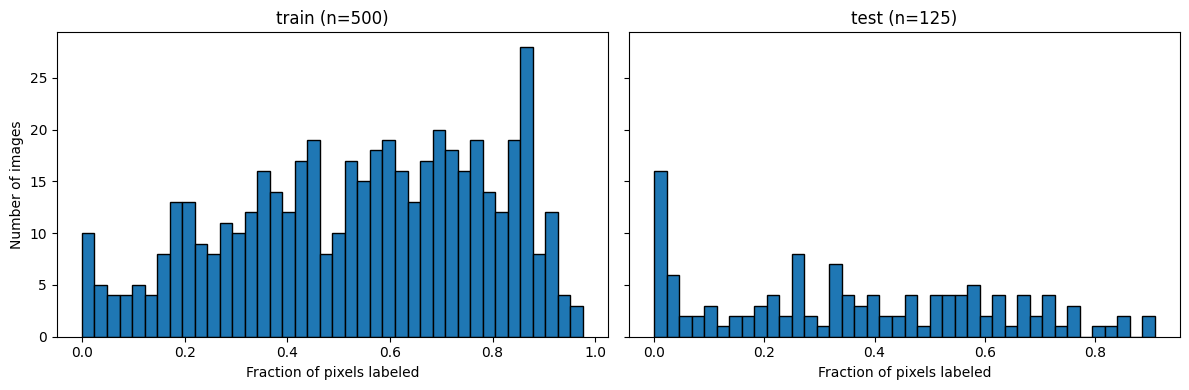

In [17]:
# Plot 1: histogram of labeled fraction

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, split in zip(axes, ["train", "test"]):
  vals = df.loc[df.split == split, "labeled_frac"]
  ax.hist(vals, bins=40, edgecolor="black")
  ax.set_title(f"{split} (n={len(vals)})")
  ax.set_xlabel("Fraction of pixels labeled")
axes[0].set_ylabel("Number of images")
plt.tight_layout()
plt.show()

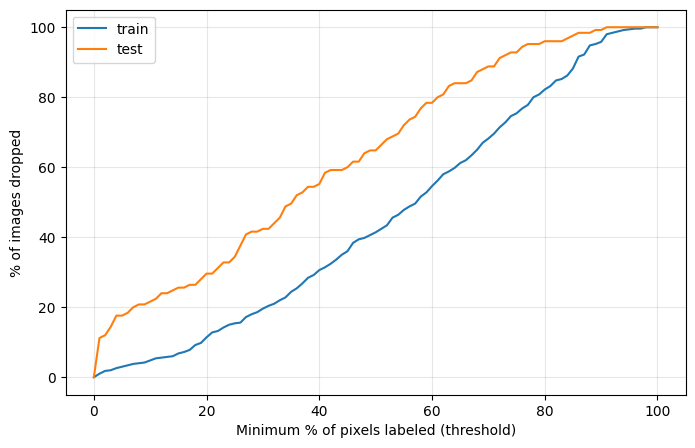

In [18]:
# Plot 2: how many images would each threshold drop?

thresholds = np.linspace(0, 1, 101)

plt.figure(figsize=(8, 5))
for split in ["train", "test"]:
  vals = df.loc[df.split == split, "labeled_frac"].values
  dropped = [(vals < t).mean() * 100 for t in thresholds]
  plt.plot(thresholds * 100, dropped, label=split)

plt.xlabel("Minimum % of pixels labeled (threshold)")
plt.ylabel("% of images dropped")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [19]:
# Apply the threshold

THRESHOLD = 0.10  # may change later

# Keep all test images; only filter train
df["keep"] = (df["split"] == "test") | (df["labeled_frac"] >= THRESHOLD)

print(df.groupby("split")["keep"].agg(kept="sum", total="count"))
print(f"Dropped: {(~df.keep).sum()} of {len(df)}")

df.to_csv("sample_split_filtered.csv", index=False)

df_kept = df[df.keep]
print(df_kept.shape)

       kept  total
split             
test    125    125
train   476    500
Dropped: 24 of 625
(601, 9)


# Task #4: Pixel Count

In [20]:
import os
import glob
import random
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Load the dataset
path = kagglehub.dataset_download(
    "yash92328/ai4mars-terrainaware-autonomous-driving-on-mars"
)
MSL = glob.glob(os.path.join(path, "**", "msl"), recursive=True)[0]
TRAIN_LABEL_DIR = os.path.join(MSL, "labels", "train")
NULL_VALUE = 255

# Use the same 500-image training subset as Task 1
train_labels = sorted(
    f for f in os.listdir(TRAIN_LABEL_DIR) if f.endswith(".png")
)
random.seed(42)
train_sample = random.sample(train_labels, 500)

CLASSES = [0, 1, 2, 3]
CLASS_LABELS = ["soil", "bedrock", "sand", "big rock"]
N = len(train_sample)

pixel_counts = np.zeros(len(CLASSES), dtype=np.int64)
image_counts = np.zeros(len(CLASSES), dtype=np.int64)
heat = None
labeled_total = 0
resized = 0

In [21]:
# Count pixels and images containing each class
for f in train_sample:
  with Image.open(os.path.join(TRAIN_LABEL_DIR, f)) as img:
    label = np.array(img)

  counts = np.bincount(label[label != NULL_VALUE], minlength=len(CLASSES))
  pixel_counts += counts
  image_counts += counts > 0
  labeled_total += (label != NULL_VALUE).sum()

  # Resize only for the heatmaps; pixel counts use the original size
  if heat is None:
    heat = np.zeros((len(CLASSES),) + label.shape)
  if label.shape != heat.shape[1:]:
    label = np.array(Image.fromarray(label).resize(
        (heat.shape[2], heat.shape[1]), resample=Image.NEAREST
    ))
    resized += 1

  for c in CLASSES:
    heat[c] += label == c

heat /= N

500 training images, heatmap size 1024x1024, 0 masks resized
   class    pixels  % of labeled pixels  images with class  % of images
    soil 105264360                37.10                252         50.4
 bedrock 140456739                49.50                323         64.6
    sand  34015503                11.99                179         35.8
big rock   4016638                 1.42                 80         16.0


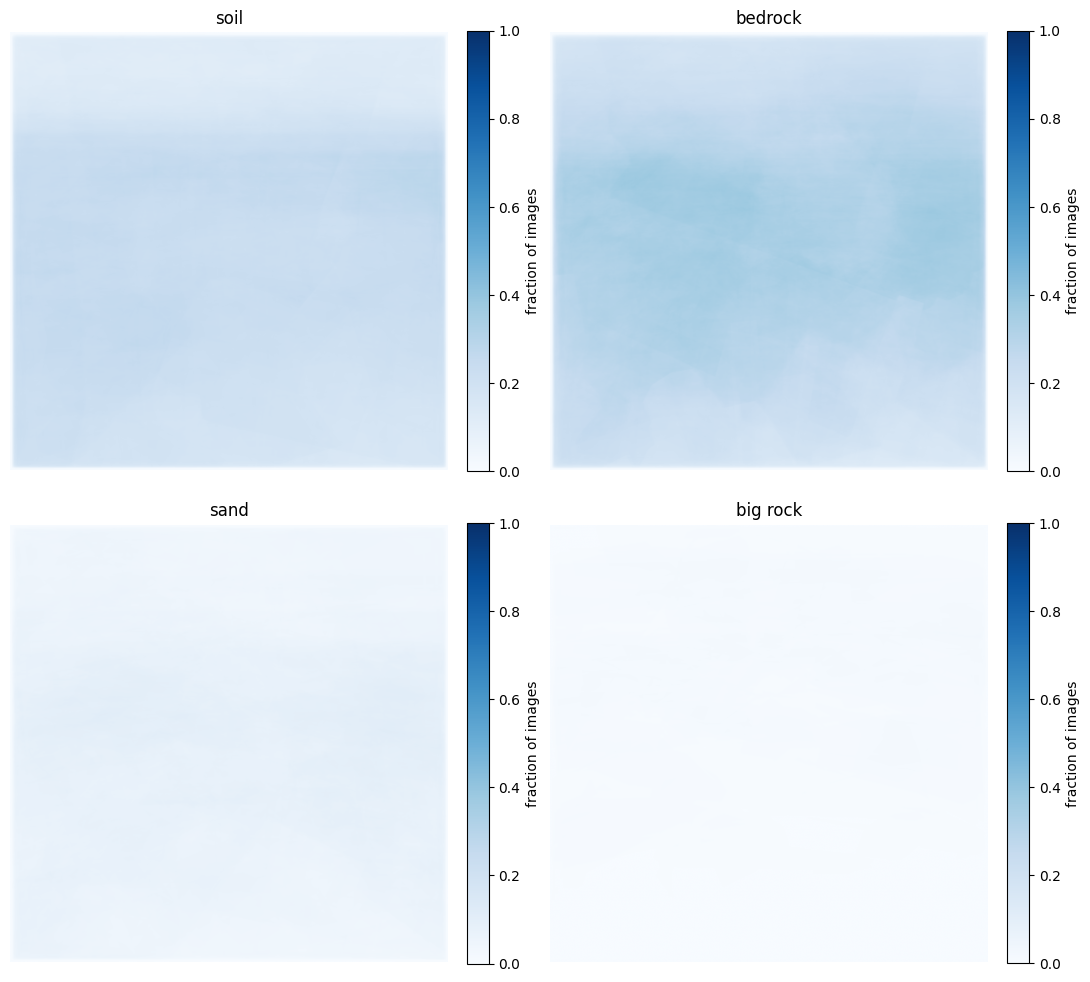

In [22]:
# Sanity checks
assert pixel_counts.sum() == labeled_total
assert (image_counts <= N).all()
assert heat.min() >= 0 and heat.max() <= 1

print(f"{N} training images, heatmap size {heat.shape[1]}x{heat.shape[2]}, {resized} masks resized")

# Class summary (excluding void/null pixels)
summary = pd.DataFrame({
    "class": CLASS_LABELS,
    "pixels": pixel_counts,
    "% of labeled pixels": (
        pixel_counts / max(labeled_total, 1) * 100
    ).round(2),
    "images with class": image_counts,
    "% of images": (image_counts / N * 100).round(1),
})
print(summary.to_string(index=False))

# Heatmaps: fraction of sampled images with each class at each position
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, c in zip(axes.flat, CLASSES):
  im = ax.imshow(heat[c], cmap="Blues", vmin=0, vmax=1, origin="upper")
  ax.set_title(CLASS_LABELS[c])
  ax.axis("off")
  fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="fraction of images")

plt.tight_layout()
plt.show()

# Task #6 and # 7 : Map Class to more Distrinct Colors

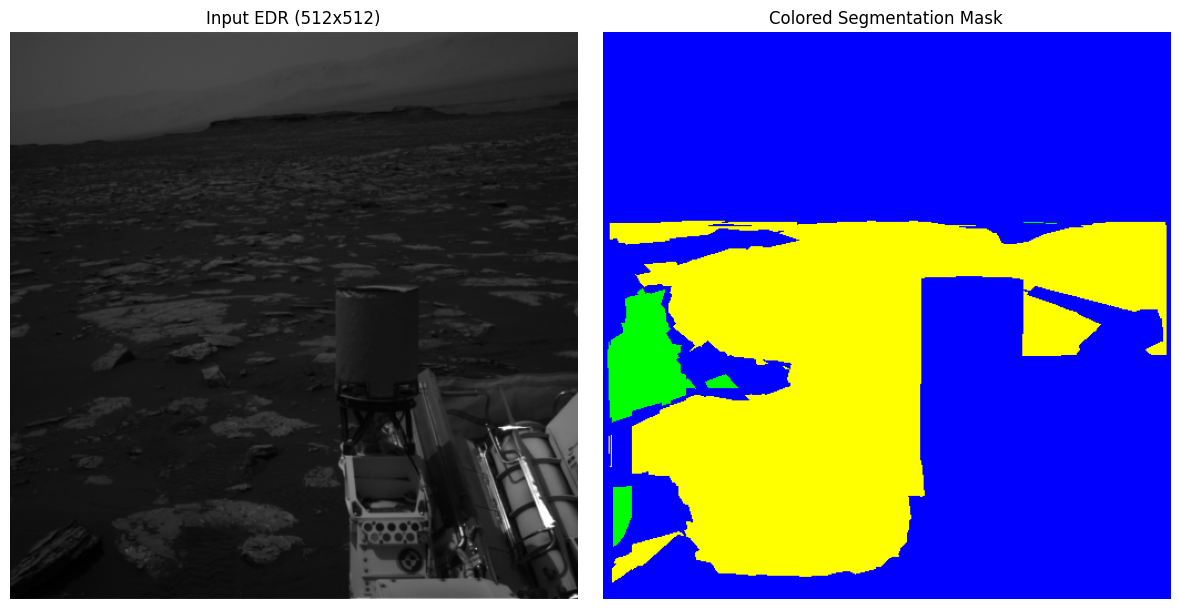

In [23]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

target_size = (512, 512)

color_map = {
    0 : [255, 0, 0],
    1 : [255, 255, 0],
    2 : [0, 255, 0],
    3 : [0, 255, 255],
    255 : [0, 0, 255],
}

class_names = {
    0 : "soil",
    1 : "bedrock",
    2 : "sand",
    3 : "Big Rock",
    255 :"void/null"
}

def load_and_resize (edr_path,label_path, target_size = target_size):
    edr_image = Image.open(edr_path).convert('L')
    edr_resized = edr_image.resize(target_size, resample = Image.BILINEAR)
    edr_arr = np.array(edr_resized)

    label_img = Image.open(label_path)
    label_resized = label_img.resize(target_size , resample = Image.NEAREST)
    label_arr = np.array(label_resized)

    return edr_arr, label_arr

def colorize_mask (label_arr):
    colored_mask = np.zeros((512, 512, 3), dtype = np.uint8)

    for class_ids, colors in color_map.items() :
        colored_mask[label_arr == class_ids] = colors
    return colored_mask

sample = df_kept.iloc[0]
sample_edr = os.path.join(MSL, sample['edr'])
sample_label = os.path.join(MSL, sample['label'])

edr_arr, label_arr = load_and_resize(sample_edr, sample_label)
colored_mask = colorize_mask(label_arr)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(edr_arr, cmap='gray')
axes[0].set_title(f"Input EDR ({target_size[0]}x{target_size[1]})")
axes[0].axis('off')

axes[1].imshow(colored_mask)
axes[1].set_title("Colored Segmentation Mask")
axes[1].axis('off')

plt.tight_layout()
plt.show()


In [24]:
import os
import zipfile
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

local_extract_path = '/content/ai4mars_subset'
os.makedirs(local_extract_path, exist_ok=True)

zip_drive_path = '/content/drive/MyDrive/AI4Mars_Subset/ai4mars_subset.zip'
if len(os.listdir(local_extract_path)) == 0:
    print("Extracting subset from Google Drive... This is much faster than downloading the full dataset!")
    with zipfile.ZipFile(zip_drive_path, 'r') as zip_ref:
        zip_ref.extractall(local_extract_path)
    print("Extraction complete!")
else:
    print("Subset already extracted locally.")

MSL = local_extract_path
print("MSL root path is now set to:", MSL)

df_kept = pd.read_csv('/content/drive/MyDrive/AI4Mars_Subset/sample_split_filtered.csv')
print(f"Loaded metadata successfully. Total active samples: {len(df_kept)}")

Mounted at /content/drive
Extracting subset from Google Drive... This is much faster than downloading the full dataset!
Extraction complete!
MSL root path is now set to: /content/ai4mars_subset
Loaded metadata successfully. Total active samples: 839


In [25]:
import albumentations as A
import cv2
import os
import pandas as pd
import numpy as np

df_aug = df_kept.copy()
df_aug["is_flipped"] = False

df_flip = df_aug.sample(frac = 0.5, random_state = 42).copy()
df_flip["is_flipped"] = True
df_aug = pd.concat([df_aug, df_flip], ignore_index = True)

np.random.seed(42)
df_aug["is_brightened"] = np.random.choice([True, False], size=len(df_aug), p=[0.5, 0.5])


print(df_aug[["split", "edr", "label", "is_flipped", "is_brightened"]])
print("Total expanded rows:", len(df_aug))


      split                                                edr  \
0     train  images/edr/NLB_532342701EDR_F0592578NCAM00279M...   
1     train  images/edr/NLB_424934381EDR_F0060658NCAM00247M...   
2     train  images/edr/NLA_402816098EDR_F0050104NCAM00451M...   
3     train  images/edr/NLB_550280573EDR_F0633092NCAM00312M...   
4     train  images/edr/NLB_454665258EDR_F0331036NCAM00293M...   
...     ...                                                ...   
1254  train  images/edr/NLB_491504824EDR_F0482542NCAM00225M...   
1255   test  images/edr/NLB_542734240EDR_F0612232NCAM00283M...   
1256  train  images/edr/NLB_550280573EDR_F0633092NCAM00312M...   
1257  train  images/edr/NLA_401400251EDR_F0042002NCAM00202M...   
1258  train  images/edr/NLB_511834352EDR_F0531994NCAM00256M...   

                                                  label  is_flipped  \
0     labels/train/NLB_532342701EDR_F0592578NCAM0027...       False   
1     labels/train/NLB_424934381EDR_F0060658NCAM0024...       Fal

In [31]:
# settings and creating dataset
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "segmentation-models-pytorch"], check=True)
import segmentation_models_pytorch as smp

import os
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
import albumentations as A

# Configuration
IMG_SIZE = (256, 256)
NUM_CLASSES = 4
IGNORE = 255
BATCH = 16
LR = 0.0001
EPOCHS = 20
CLASS_NAMES = ["soil", "bedrock", "sand", "big rock"]

# Pretrained ImageNet normalization values
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42)
print("device:", device)

MSL = "/content/ai4mars_subset"

# 1. Load Data
try:
    df_kept
except NameError:
    df_kept = pd.read_csv("/content/drive/MyDrive/AI4Mars_Subset/sample_split_filtered.csv")

if "keep" in df_kept.columns:
    df_kept = df_kept[df_kept["keep"] == True]

train_df = df_kept[df_kept["split"] == "train"].reset_index(drop=True)
val_df = df_kept[df_kept["split"] == "test"].reset_index(drop=True).copy()

val_df["label"] = val_df["label"].str.replace("min3-100agree", "min2-100agree", regex=False)
has_min2 = val_df["label"].apply(lambda p: os.path.exists(os.path.join(MSL, p)))
val_df = val_df[has_min2].reset_index(drop=True)

# 2. Expand Training DataFrame for Augmentations
train_df_aug = train_df.copy()
train_df_aug["is_flipped"] = False

# Duplicate 50% for horizontal flip
df_flip = train_df_aug.sample(frac=0.5, random_state=42).copy()
df_flip["is_flipped"] = True
train_df_aug = pd.concat([train_df_aug, df_flip], ignore_index=True)

# Randomly flag 50% for brightness adjustment
np.random.seed(42)
train_df_aug["is_brightened"] = np.random.choice([True, False], size=len(train_df_aug), p=[0.5, 0.5])
train_df_aug = train_df_aug.reset_index(drop=True)

print(f"train (expanded with augs): {len(train_df_aug)} | validation: {len(val_df)}")

# 3. Define Augmentation Transforms
flip_transform = A.HorizontalFlip(p=1.0)
bright_transform = A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=1.0)

# 4. Define PyTorch Dataset Class
class AI4MarsDataset(Dataset):
    def __init__(self, df, base_path, target_size=IMG_SIZE, is_train=True):
        self.df = df
        self.base_path = base_path
        self.target_size = target_size
        self.is_train = is_train

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        img_col = "edr" if "edr" in row else "image"
        img_path = os.path.join(self.base_path, row[img_col])
        mask_path = os.path.join(self.base_path, row["label"])

        image = cv2.imread(img_path, cv2.IMREAD_COLOR)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        image = cv2.resize(image, self.target_size, interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, self.target_size, interpolation=cv2.INTER_NEAREST)

        # Apply augmentations based on DataFrame flags
        if self.is_train:
            if row.get("is_flipped", False):
                augmented = flip_transform(image=image, mask=mask)
                image, mask = augmented["image"], augmented["mask"]

            if row.get("is_brightened", False):
                augmented = bright_transform(image=image)
                image = augmented["image"]

        # Convert image to Tensor & apply ImageNet normalization
        image_tensor = torch.from_numpy(image).permute(2, 0, 1).float() / 255.0
        image_tensor = TF.normalize(image_tensor, MEAN, STD)

        # Mask as Long Tensor for CrossEntropy/Jaccard Loss
        mask_tensor = torch.from_numpy(mask).long()

        return image_tensor, mask_tensor

# 5. Instantiate Datasets & DataLoaders
pin = device == "cuda"
train_dataset = AI4MarsDataset(train_df_aug, MSL, target_size=IMG_SIZE, is_train=True)
val_dataset = AI4MarsDataset(val_df, MSL, target_size=IMG_SIZE, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH, shuffle=True, num_workers=2, pin_memory=pin, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=pin)

# 6. Sanity check batch shape and values
xb, yb = next(iter(train_loader))
print("batch image shape:", tuple(xb.shape))
print("batch mask shape:", tuple(yb.shape))
print("label values present in batch:", torch.unique(yb).tolist())

device: cuda
train (expanded with augs): 1071 | validation: 125
batch image shape: (16, 3, 256, 256)
batch mask shape: (16, 256, 256)
label values present in batch: [0, 1, 2, 3, 255]


In [32]:
# Cell 3: Model, loss, optimizer
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp

# Create model (activation=None outputs raw logits needed for PyTorch losses)
model = smp.DeepLabV3(
    encoder_name="resnet50",
    encoder_weights="imagenet",
    in_channels=3,
    classes=NUM_CLASSES,
    activation=None,  # Standard: Output raw logits
).to(device)

# Standard loss function that ignores unlabeled pixels automatically
criterion = nn.CrossEntropyLoss(ignore_index=IGNORE)

# Optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=LR)


In [33]:
import random

# Set all random seeds
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# Ensure CUDA operations are completely deterministic
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

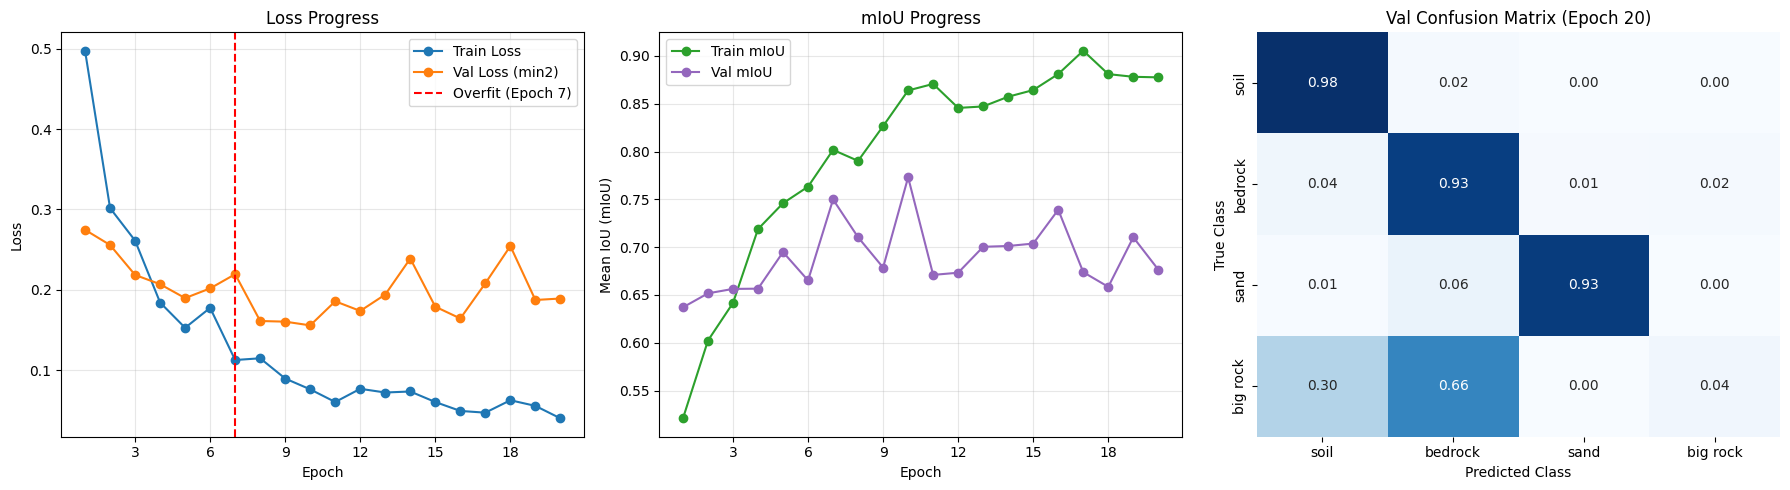

epoch 01 | train loss 0.4976 | train mIoU 0.5210 | val loss 0.2746 | val mIoU 0.6371
epoch 02 | train loss 0.3017 | train mIoU 0.6023 | val loss 0.2557 | val mIoU 0.6517
epoch 03 | train loss 0.2612 | train mIoU 0.6416 | val loss 0.2184 | val mIoU 0.6563
epoch 04 | train loss 0.1841 | train mIoU 0.7189 | val loss 0.2069 | val mIoU 0.6566
epoch 05 | train loss 0.1526 | train mIoU 0.7460 | val loss 0.1896 | val mIoU 0.6948
epoch 06 | train loss 0.1774 | train mIoU 0.7633 | val loss 0.2017 | val mIoU 0.6652
epoch 07 | train loss 0.1125 | train mIoU 0.8017 | val loss 0.2194 | val mIoU 0.7499 [OVERFITTING DETECTED]
epoch 08 | train loss 0.1146 | train mIoU 0.7902 | val loss 0.1611 | val mIoU 0.7103
epoch 09 | train loss 0.0894 | train mIoU 0.8266 | val loss 0.1603 | val mIoU 0.6787
epoch 10 | train loss 0.0759 | train mIoU 0.8639 | val loss 0.1556 | val mIoU 0.7730
epoch 11 | train loss 0.0602 | train mIoU 0.8707 | val loss 0.1856 | val mIoU 0.6710
epoch 12 | train loss 0.0766 | train mIoU 

In [34]:
# Cell 4: Train with accuracy tracking, per-epoch confusion matrix, and overfitting detection
# Cell 4: Train with Loss, mIoU tracking, dashboard plotting, and automatic Git push
import os
import subprocess
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import torch
from IPython.display import clear_output
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import confusion_matrix

# --- GIT CONFIGURATION (Update these variables) ---
GITHUB_TOKEN = "your_personal_access_token"  # GitHub PAT with 'repo' scope
GITHUB_REPO = "username/repository-name"    # e.g., "myuser/mars-segmentation"
TARGET_BRANCH = "results-branch"             # The branch to push graphs to
USER_NAME = "Your Name"
USER_EMAIL = "your.email@example.com"
# --------------------------------------------------

train_losses, val_losses = [], []
train_mious, val_mious = [], []
log = []

# Overfitting detection variables
best_val_loss = float("inf")
overfit_epoch = None
patience = 2
patience_counter = 0

def calculate_iou_and_acc(logits, targets, num_classes=NUM_CLASSES, ignore_index=IGNORE):
    """Calculates Mean IoU (mIoU) and Pixel Accuracy ignoring unlabeled pixels."""
    preds = torch.argmax(logits, dim=1).cpu().numpy()
    targets = targets.cpu().numpy()

    mask = targets != ignore_index
    preds_valid = preds[mask]
    targets_valid = targets[mask]

    # Pixel Accuracy
    correct = (preds_valid == targets_valid).sum()
    total_pixels = mask.sum()

    # Per-class IoU
    ious = []
    for cls in range(num_classes):
        intersection = ((preds_valid == cls) & (targets_valid == cls)).sum()
        union = ((preds_valid == cls) | (targets_valid == cls)).sum()
        if union > 0:
            ious.append(intersection / union)

    miou = np.mean(ious) if len(ious) > 0 else 0.0
    return miou, correct, total_pixels

def plot_and_save_dashboard(latest_cm):
    clear_output(wait=True)
    epochs = range(1, len(train_losses) + 1)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Panel 1: Loss Curve
    axes[0].plot(epochs, train_losses, marker="o", label="Train Loss", color="tab:blue")
    axes[0].plot(epochs, val_losses, marker="o", label="Val Loss (min2)", color="tab:orange")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title("Loss Progress")
    axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
    axes[0].grid(alpha=0.3)
    if overfit_epoch is not None:
        axes[0].axvline(x=overfit_epoch, color="red", linestyle="--", label=f"Overfit (Epoch {overfit_epoch})")
    axes[0].legend()

    # Panel 2: Mean IoU (mIoU) Curve
    axes[1].plot(epochs, train_mious, marker="o", label="Train mIoU", color="tab:green")
    axes[1].plot(epochs, val_mious, marker="o", label="Val mIoU", color="tab:purple")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Mean IoU (mIoU)")
    axes[1].set_title("mIoU Progress")
    axes[1].xaxis.set_major_locator(MaxNLocator(integer=True))
    axes[1].grid(alpha=0.3)
    axes[1].legend()

    # Panel 3: Confusion Matrix
    cm_norm = latest_cm.astype("float") / (latest_cm.sum(axis=1, keepdims=True) + 1e-7)
    sns.heatmap(
        cm_norm, annot=True, fmt=".2f", cmap="Blues",
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
        ax=axes[2], cbar=False
    )
    axes[2].set_xlabel("Predicted Class")
    axes[2].set_ylabel("True Class")
    axes[2].set_title(f"Val Confusion Matrix (Epoch {len(train_losses)})")

    plt.tight_layout()
    plt.savefig("loss_and_miou_dashboard.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("\n".join(log))

def push_results_to_git():
    """Pushes generated graphs and checkpoint to the specified Git branch."""
    print("\n--- Pushing results to Git repository ---")
    try:
        # Set up git user
        subprocess.run(["git", "config", "--global", "user.name", USER_NAME], check=True)
        subprocess.run(["git", "config", "--global", "user.email", USER_EMAIL], check=True)

        # Authenticated remote URL
        remote_url = f"https://{GITHUB_TOKEN}@github.com/{GITHUB_REPO}.git"

        # Checkout/create target branch and push
        subprocess.run(["git", "checkout", "-B", TARGET_BRANCH], check=True)
        subprocess.run(["git", "add", "loss_and_miou_dashboard.png", "deeplabv3_smp.pt"], check=True)
        subprocess.run(["git", "commit", "-m", f"Automated commit: Training loss/mIoU graphs (Epoch {len(train_losses)})"], check=True)
        subprocess.run(["git", "push", "-u", remote_url, TARGET_BRANCH, "--force"], check=True)
        print(f"Successfully pushed graphs and checkpoint to branch '{TARGET_BRANCH}'!")
    except Exception as e:
        print(f"Failed to push to Git: {e}")

# --- TRAINING LOOP ---
for epoch in range(1, EPOCHS + 1):
    # Train
    model.train()
    total_loss, train_miou_sum = 0.0, 0.0

    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()

        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        miou, _, _ = calculate_iou_and_acc(logits, y)
        train_miou_sum += miou

    epoch_train_loss = total_loss / len(train_loader.dataset)
    epoch_train_miou = train_miou_sum / len(train_loader)
    train_losses.append(epoch_train_loss)
    train_mious.append(epoch_train_miou)

    # Validate
    model.eval()
    total_loss, val_miou_sum = 0.0, 0.0
    val_preds_all, val_targets_all = [], []

    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = criterion(logits, y).item()

            if np.isfinite(loss):
                total_loss += loss * x.size(0)

            miou, _, _ = calculate_iou_and_acc(logits, y)
            val_miou_sum += miou

            preds = torch.argmax(logits, dim=1)
            valid_mask = (y != IGNORE)
            val_preds_all.append(preds[valid_mask].cpu().numpy())
            val_targets_all.append(y[valid_mask].cpu().numpy())

    epoch_val_loss = total_loss / len(val_loader.dataset)
    epoch_val_miou = val_miou_sum / len(val_loader)
    val_losses.append(epoch_val_loss)
    val_mious.append(epoch_val_miou)

    flat_preds = np.concatenate(val_preds_all)
    flat_targets = np.concatenate(val_targets_all)
    cm = confusion_matrix(flat_targets, flat_preds, labels=list(range(NUM_CLASSES)))

    # Check overfitting
    if overfit_epoch is None:
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                overfit_epoch = epoch

    status = f"epoch {epoch:02d} | train loss {epoch_train_loss:.4f} | train mIoU {epoch_train_miou:.4f} | val loss {epoch_val_loss:.4f} | val mIoU {epoch_val_miou:.4f}"
    if overfit_epoch == epoch:
        status += " [OVERFITTING DETECTED]"
    log.append(status)

    plot_and_save_dashboard(cm)

# Save checkpoint locally and to Google Drive
CKPT = "deeplabv3_smp.pt"
torch.save(model.state_dict(), CKPT)
!mkdir -p /content/drive/MyDrive/MarsSegmentation/
!cp deeplabv3_smp.pt /content/drive/MyDrive/MarsSegmentation/

# Push loss & mIoU graph to GitHub branch
push_results_to_git()